# Data Analysis & Preparation

Cleans and explores the song catalog, including genre aggregation.

> Generated from `Lab2_multi_task_modal.ipynb`.

# Song Recommendation With Multi-Task Learning

## Dataset Overview

### Dataset Feature Format and Multi-Task Explanation

For this assignment I am using a Spotify song dataset. This dataset contains songs from approximatesly 10,000 playlists. Features and metadata about the songs are obtained using Spotify API. Features include danceablilty. liveness, key, mode (major or minor), speechiness, acousticness, instrumentalness, liveness, and valence (happy or sad). Metadata about the songs include song name, artist name, artist genre, artist popularity, and song popularity. For my purposes I am only using song features and genres to train my model. This sums to a total of 11 feaure vectors and 1 genre per song. Spotify provides a list of genres that pertain to a given artist, however I only use the first genre in the list since it is the most prominent. Since there are about 1300 genres, I will be aggregating each song into 1 of 26 genre groups. <br><br>

After aggregating the songs into genre groups, I create a latent space of 12 dimensions with a Variational Autoencoder (VAE). I use a VAE so my latent space exhibits smoothness and distances between points in the latent space are meaningful.<br><br>

Once I have plotted my songs in the latent space, I create a list of genre groups for 3 different activities: exercising, relaxing and commuting. I chose genres with higher energy for exercise, lower energy for relaxing and genres in-between for commuting. Multiple genres can exist in multiple different activity lists.<br><br>

I use these genres to simulate user preferences for different activities. While this can scale to generating many different users, I am using 3 in this study. To generate a user, I randomly choose 1 genre from each activity list to represent their preferences. I then calculate the location of the centroid of the given genres in the latent space. All songs that fall within 1 standard of deviation away from this centroid represent a song that the user would like for that activity these songs can span outside of the given genre. I then introduce randomness by randomly removing 10% of the songs within the centroid radius and adding an equivalent number of song from outside of the radius to the preferences. This randomness is to better simulate a real human's tastes. After I assign the user preferences to each song, my dataset is ready for multi-task learning.<br><br>

The classification task at hand is to predict whether or not a user would listen to a given song for each activity. It is possible for a user to like one song for multiple activities. This is a multi-task learning problem where predicting preferences for each user is an individual task. I am using 3 users so I have 3 tasks.<br><br>

### Source of Data

This data was originallly released as a part of the [Spotify Million Playlist Dataset challenge](https://www.aicrowd.com/challenges/spotify-million-playlist-dataset-challenge)  from AICrowd. This data was released as an AI challenge for creating and experimenting with music recommendation models. The dataset released by AICrowd is in JSON format with limited information about each song including name and ID. In order to retrieve metadata and features about each song, one must iterate through the JSON files and use Spotify's API calls.<br><br>

This process is extremely time consuming as the dataset is huge and Spotify API throttles the number of API calls that can be made per second. The dataset I'm using was retrieved by Eric Chang for use in an [educational medium article](https://towardsdatascience.com/part-iii-building-a-song-recommendation-system-with-spotify-cf76b52705e7) walking through basic music recommendation in python. The authors open-sourced the data on GitHub. The dataset contains features and metadata retrieved from a subset of 10,000 playlists of the original dataset. 

### Evaluation Criteria

My learning task is multiple binary classification. My model will output three units, each will represent whether or not the user would listen to the given song for each activity. For evaluating this model I will be using an AUC score for each individual activity or each individual user as it represents how well a model can distinguish between positive and negative classes ini binary classification. I will visualize these evauluations using an AUC-ROC curve. I will compare the performance on each task between users and the general model. I will also aggregate the predictions over all users in the multi-task model and evaluate with an AUC score.<br><br>

Since the majority of the songs in my dataset are not within the preferences of each user, I am using balanced class weighting to avoid a bias toward always classifying the song as false for all activities.



## Loading Data and Preprocessing

In [1]:
import pandas as pd
import numpy as np
import ast
import os
from sklearn.model_selection import train_test_split
from tqdm import tqdm
from sklearn.preprocessing import OneHotEncoder, StandardScaler
import numpy as np
import tensorflow as tf
import tensorflow.keras
import keras
from tensorflow.keras import layers
from keras.models import Sequential
from matplotlib.colors import ListedColormap
import matplotlib.pyplot as plt
import plotly.io as plt_io
import plotly.graph_objects as go
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import LabelEncoder
import plotly.express as px
import itertools
from sklearn.utils import class_weight
from tensorflow.keras.models import Model
import random
from sklearn.metrics import confusion_matrix, f1_score, roc_auc_score, roc_curve, auc, classification_report
%matplotlib inline

In [2]:
import os
print("Current working directory:", os.getcwd())
print("Files in this directory:", os.listdir())
songs_df = pd.read_csv('../../data/cleaned_songs.csv')
songs_df

Current working directory: /Users/lucasmusselman/Documents/GitHub/Capstone_Playlist_Creator/Model/notebooks
Files in this directory: ['03_encoder_inference.ipynb', '04_multitask_training.ipynb', '05_multitask_inference.ipynb', '02b_aae_encoder_training.ipynb', 'README.md', '02_encoder_training.ipynb', '01_data_analysis.ipynb']


,artist_name,id,track_name,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,artist_pop,genres,track_pop,genres_list,subjectivity,polarity
0,Missy Elliott,0UaMYEvWZi0ZqiDOoHU3YI,Lose Control (feat. Ciara & Fat Man Scoop),0.904,0.813,4,-7.105,0,0.1210,0.03110,0.006970,0.0471,0.810,125.461,74,dance_pop hip_hop hip_pop pop pop_rap r&b rap ...,69,"['dance_pop', 'hip_hop', 'hip_pop', 'pop', 'po...",low,Neutral
1,Britney Spears,6I9VzXrHxO9rA9A5euc8Ak,Toxic,0.774,0.838,5,-3.914,0,0.1140,0.02490,0.025000,0.2420,0.924,143.040,84,dance_pop pop post-teen_pop,83,"['dance_pop', 'pop', 'post-teen_pop']",low,Neutral
2,Beyoncé,0WqIKmW4BTrj3eJFmnCKMv,Crazy In Love,0.664,0.758,2,-6.583,0,0.2100,0.00238,0.000000,0.0598,0.701,99.259,86,dance_pop pop r&b,25,"['dance_pop', 'pop', 'r&b']",high,Negative
3,Justin Timberlake,1AWQoqb9bSvzTjaLralEkT,Rock Your Body,0.892,0.714,4,-6.055,0,0.1410,0.20100,0.000234,0.0521,0.817,100.972,82,dance_pop pop,79,"['dance_pop', 'pop']",low,Neutral
4,Shaggy,1lzr43nnXAijIGYnCT8M8H,It Wasn't Me,0.853,0.606,0,-4.596,1,0.0713,0.05610,0.000000,0.3130,0.654,94.759,75,pop_rap reggae_fusion,2,"['pop_rap', 'reggae_fusion']",low,Neutral
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
34242,Jon D,3uCHI1gfOUL5j5swEh0TcH,I Don't Know,0.669,0.228,2,-12.119,1,0.0690,0.79200,0.065000,0.0944,0.402,83.024,47,unknown,27,['unknown'],low,Neutral
34243,Big Words,0P1oO2gREMYUCoOkzYAyFu,The Answer,0.493,0.727,1,-5.031,1,0.2170,0.08730,0.000000,0.1290,0.289,73.259,39,australian_r&b,37,['australian_r&b'],low,Neutral
34244,Allan Rayman,2oM4BuruDnEvk59IvIXCwn,25.22,0.702,0.524,7,-10.710,1,0.0793,0.33200,0.055300,0.2980,0.265,140.089,55,canadian_contemporary_r&b modern_alternative_rock,49,"['canadian_contemporary_r&b', 'modern_alternat...",low,Neutral
34245,Jon Jason,4Ri5TTUgjM96tbQZd5Ua7V,Good Feeling,0.509,0.286,8,-14.722,1,0.1230,0.40200,0.000012,0.1310,0.259,121.633,4,unknown,16,['unknown'],high,Positive


In [3]:
# drop rows with identical artist_name and track_name
songs_df = songs_df.drop_duplicates(subset=['artist_name', 'track_name'], keep='first')
#add column with the first item in the genres list
songs_df['genre'] = songs_df['genres_list'].apply(lambda x: ast.literal_eval(x)[0])
#drop subjectivity, polarity, genres, genre list and identifiers
songs_df = songs_df.drop(columns=['subjectivity', 'polarity', 'genres', 'genres_list', 'track_name', 'artist_name', 'id'])
#drop rows with unknown genre
songs_df = songs_df[songs_df['genre'] != 'unknown']
songs_df.head(25)


,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,artist_pop,track_pop,genre
0,0.904,0.813,4,-7.105,0,0.1210,0.031100,0.006970,0.0471,0.810,125.461,74,69,dance_pop
1,0.774,0.838,5,-3.914,0,0.1140,0.024900,0.025000,0.2420,0.924,143.040,84,83,dance_pop
2,0.664,0.758,2,-6.583,0,0.2100,0.002380,0.000000,0.0598,0.701,99.259,86,25,dance_pop
3,0.892,0.714,4,-6.055,0,0.1410,0.201000,0.000234,0.0521,0.817,100.972,82,79,dance_pop
4,0.853,0.606,0,-4.596,1,0.0713,0.056100,0.000000,0.3130,0.654,94.759,75,2,pop_rap
5,0.881,0.788,2,-4.669,1,0.1680,0.021200,0.000000,0.0377,0.592,104.997,82,0,atl_hip_hop
6,0.662,0.507,5,-8.238,1,0.1180,0.257000,0.000000,0.0465,0.676,86.412,82,79,atl_hip_hop
7,0.570,0.821,2,-4.380,1,0.2670,0.178000,0.000000,0.2890,0.408,210.857,72,67,dance_pop
8,0.713,0.678,5,-3.525,0,0.1020,0.273000,0.000000,0.1490,0.734,138.009,75,78,dance_pop
9,0.727,0.974,4,-2.261,0,0.0664,0.103000,0.000532,0.1740,0.965,79.526,77,82,atl_hip_hop


In [4]:
songs_df.genre.value_counts()

genre
dance_pop               2515
contemporary_country    1595
alternative_metal       1032
album_rock               729
atl_hip_hop              726
                        ... 
norwegian_hip_hop          1
steel_guitar               1
chinese_hip_hop            1
musica_potosina            1
jazz_guitar                1
Name: count, Length: 1298, dtype: int64

### Aggregating Genres into Genre Groups

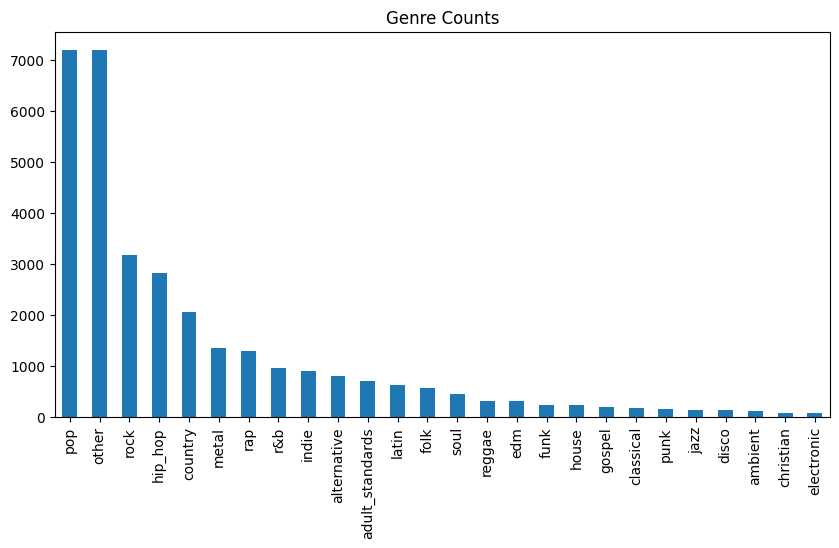

0.2234472049689441
26


In [5]:
#create empty list of length of the dataframe
genre_group = np.empty((len(songs_df), 1)).tolist()
others = []

#add a column that groups genres into categories being pop, rock, hip hop, metal, country, rap, r&b, edm, jazz, soul, blues, reggae, classical, folk
for i, genre in enumerate(songs_df['genre']):

    if 'pop' in genre:
        genre_group[i] = 'pop'
    elif 'rock' in genre:
        genre_group[i] = 'rock'
    elif 'hip_hop' in genre:
        genre_group[i] = 'hip_hop'
    elif 'country' in genre:
        genre_group[i] = 'country'
    elif 'rap' in genre:
        genre_group[i] = 'rap'
    elif 'r&b' in genre:
        genre_group[i] = 'r&b'
    elif 'edm' in genre:
        genre_group[i] = 'edm'
    elif 'jazz' in genre:
        genre_group[i] = 'jazz'
    elif 'soul' in genre:
        genre_group[i] = 'soul'
    elif 'reggae' in genre:
        genre_group[i] = 'reggae'
    elif 'classical' in genre:
        genre_group[i] = 'classical'
    elif 'folk' in genre:
        genre_group[i] = 'folk'
    elif 'metal' in genre:
        genre_group[i] = 'metal'
    elif 'latin' in genre:
        genre_group[i] = 'latin'
    elif 'christian' in genre:
        genre_group[i] = 'christian'
    elif 'gospel' in genre:
        genre_group[i] = 'gospel'
    elif 'indie' in genre:
        genre_group[i] = 'indie'
    elif 'electronic' in genre:
        genre_group[i] = 'electronic'
    elif 'disco' in genre:
        genre_group[i] = 'disco'
    elif 'punk' in genre:
        genre_group[i] = 'punk'
    elif 'funk' in genre:
        genre_group[i] = 'funk'
    elif 'alternative' in genre:
        genre_group[i] = 'alternative'
    elif 'ambient' in genre:
        genre_group[i] = 'ambient'
    elif 'house' in genre:
        genre_group[i] = 'house'
    elif 'adult_standards' in genre:
        genre_group[i] = 'adult_standards'
    else:
        genre_group[i] = 'other'
        others.append(genre)


#make a dictionary to translate these things dict reanslatte what to what

        
#print the value counts of the genres in a grid
pd.Series(genre_group).value_counts().plot(kind='bar', figsize=(10, 5), title='Genre Counts')
plt.show()
#find the number of items in the 'other' category
other_count = pd.Series(genre_group).value_counts()['other']
#divide the number of items in the 'other' category by the total number of items
print(other_count / len(songs_df))
#find the number of unique genres
print(len(pd.Series(genre_group).value_counts()))

In [6]:
#print the names of the genre groups
print(pd.Series(genre_group).value_counts())

pop                7198
other              7195
rock               3181
hip_hop            2821
country            2054
metal              1346
rap                1284
r&b                 963
indie               902
alternative         806
adult_standards     709
latin               627
folk                569
soul                439
reggae              312
edm                 311
funk                236
house               223
gospel              186
classical           173
punk                151
jazz                136
disco               130
ambient             117
christian            69
electronic           62
Name: count, dtype: int64


In [7]:
#add the genre_group column to the dataframe
songs_df['genre_group'] = genre_group
#drop the genre column
songs_df = songs_df.drop(columns=['genre'])

output_path = '../../data/cleaned_songs_with_groups.csv'

songs_df.to_csv(output_path, index=False)